In [24]:
import pandas as pd
import matplotlib as mpl
import seaborn as sns
from scipy.stats import skew
import matplotlib.pyplot as plt
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [25]:
df_excel= pd.read_excel("..\\raw\\D00 - wine.data.xlsx", sheet_name= 1)

df_excel.to_csv("..\\raw\\D00 - wine.data.csv", index=False, encoding= 'utf-8')

df= pd.read_csv("..\\raw\\D00 - wine.data.csv")

In [26]:
# a) Kích thước và chiều của dữ liệu
print("Kích thước (Số dòng, Số cột):", df.shape)
print("Số chiều:", df.ndim)

# b) Kiểu dữ liệu của các thuộc tính
print("\nKiểu dữ liệu:")
print(df.dtypes)

# c) Số lượng thực tế của các giá trị nhãn (Class)
print("\nPhân bố nhãn (Class):")
print(df['Class'].value_counts())

# d) Thống kê mô tả (Min, Max, Mean) cho các cột thuộc tính số thực
print("\nThống kê mô tả (Min, Max, Mean):")
desc = df.describe().T[['min', 'max', 'mean']]
print(desc)

Kích thước (Số dòng, Số cột): (178, 14)
Số chiều: 2

Kiểu dữ liệu:
Class                                int64
1) Alcohol                         float64
2) Malic acid                      float64
3) Ash                             float64
4) Alcalinity of ash               float64
5) Magnesium                         int64
6) Total phenols                   float64
7) Flavanoids                      float64
8) Nonflavanoid phenols            float64
9) Proanthocyanins                 float64
10)Color intensity                 float64
11)Hue                             float64
12)OD280/OD315 of diluted wines    float64
13)Proline                           int64
dtype: object

Phân bố nhãn (Class):
Class
2    71
1    59
3    48
Name: count, dtype: int64

Thống kê mô tả (Min, Max, Mean):
                                    min      max        mean
Class                              1.00     3.00    1.938202
1) Alcohol                        11.03    14.83   13.000618
2) Malic acid        

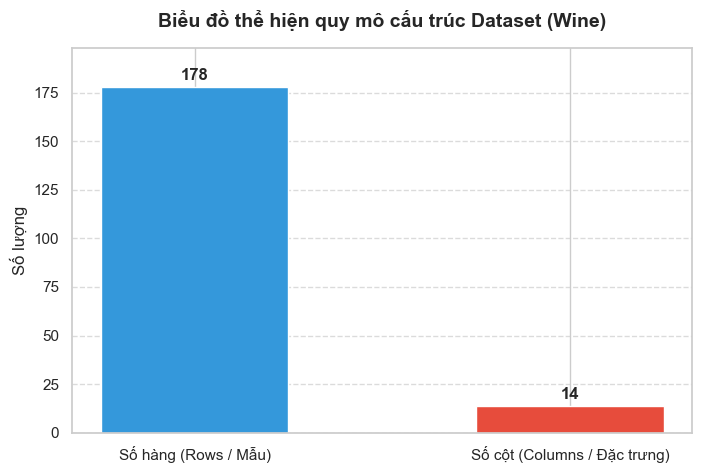

In [27]:

# Lấy số lượng hàng và số lượng cột
num_rows = df.shape[0]  # Số hàng: 178
num_cols = df.shape[1]  # Số cột: 14

# Chuẩn bị dữ liệu cho biểu đồ
categories = ['Số hàng (Rows / Mẫu)', 'Số cột (Columns / Đặc trưng)']
values = [num_rows, num_cols]

# 2. Vẽ biểu đồ cột
plt.figure(figsize=(8, 5))
bars = plt.bar(categories, values, color=['#3498db', '#e74c3c'], width=0.5)

# Thêm giá trị trực tiếp lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2,
             str(height),
             ha='center', va='bottom', fontsize=12, fontweight='bold')

# Thiết lập tiêu đề và nhãn
plt.title('Biểu đồ thể hiện quy mô cấu trúc Dataset (Wine)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Số lượng', fontsize=12)
plt.ylim(0, max(values) + 20)  # Tạo khoảng trống phía trên cho đẹp mắt
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Hiển thị biểu đồ
plt.show()

Số lượng dữ liệu theo từng nhãn:
Class
1    59
2    71
3    48
Name: count, dtype: int64


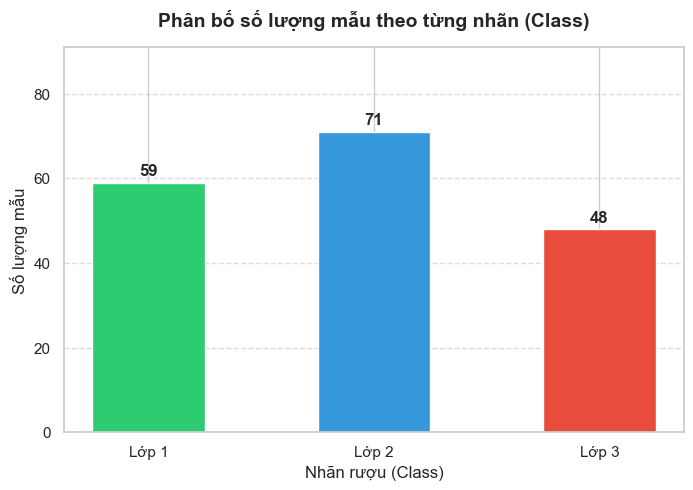

In [28]:
# Đếm số lượng mẫu của từng nhãn (Class)
class_counts = df['Class'].value_counts().sort_index()
print("Số lượng dữ liệu theo từng nhãn:")
print(class_counts)

# 2. Vẽ biểu đồ cột trực quan hóa phân bố nhãn
plt.figure(figsize=(8, 5))
bars = plt.bar(
    [f"Lớp {cls}" for cls in class_counts.index], 
    class_counts.values, 
    color=['#2ecc71', '#3498db', '#e74c3c'], 
    width=0.5
)

# Thêm giá trị cụ thể lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2., height + 1,
        str(height),
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

# Thiết lập tiêu đề và nhãn trục
plt.title('Phân bố số lượng mẫu theo từng nhãn (Class)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nhãn rượu (Class)', fontsize=12)
plt.ylabel('Số lượng mẫu', fontsize=12)
plt.ylim(0, max(class_counts.values) + 20)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Hiển thị biểu đồ
plt.show()

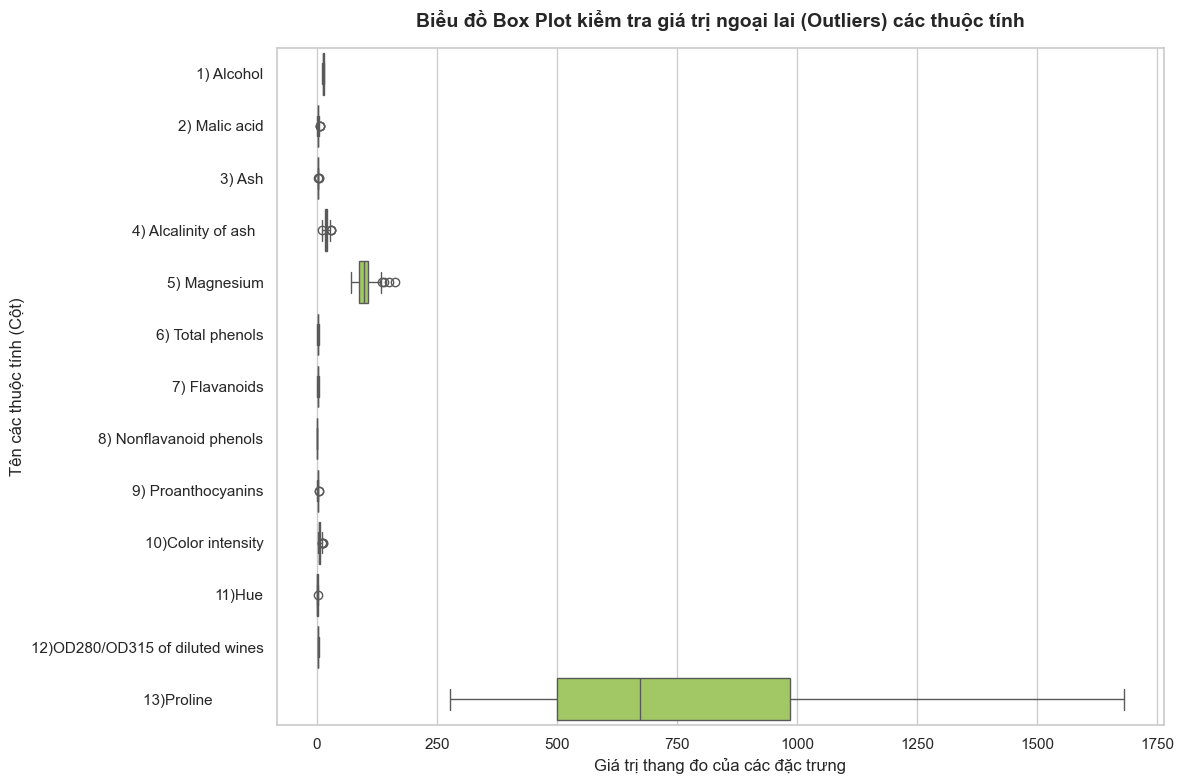

In [29]:
# Loại bỏ cột 'Class' (nhãn) vì đây là biến phân loại, chỉ giữ lại các cột đặc trưng số thực để vẽ Box Plot
df_features = df.drop(columns=['Class'])

# 2. Thiết lập biểu đồ Box Plot
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# Vẽ box plot theo chiều ngang (orient='h') để dễ đọc tên các thuộc tính
sns.boxplot(data=df_features, orient='h', palette='Set2')

# Thiết lập tiêu đề và nhãn
plt.title('Biểu đồ Box Plot kiểm tra giá trị ngoại lai (Outliers) các thuộc tính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Giá trị thang đo của các đặc trưng', fontsize=12)
plt.ylabel('Tên các thuộc tính (Cột)', fontsize=12)

# Tinh chỉnh bố cục và hiển thị
plt.tight_layout()
plt.show()

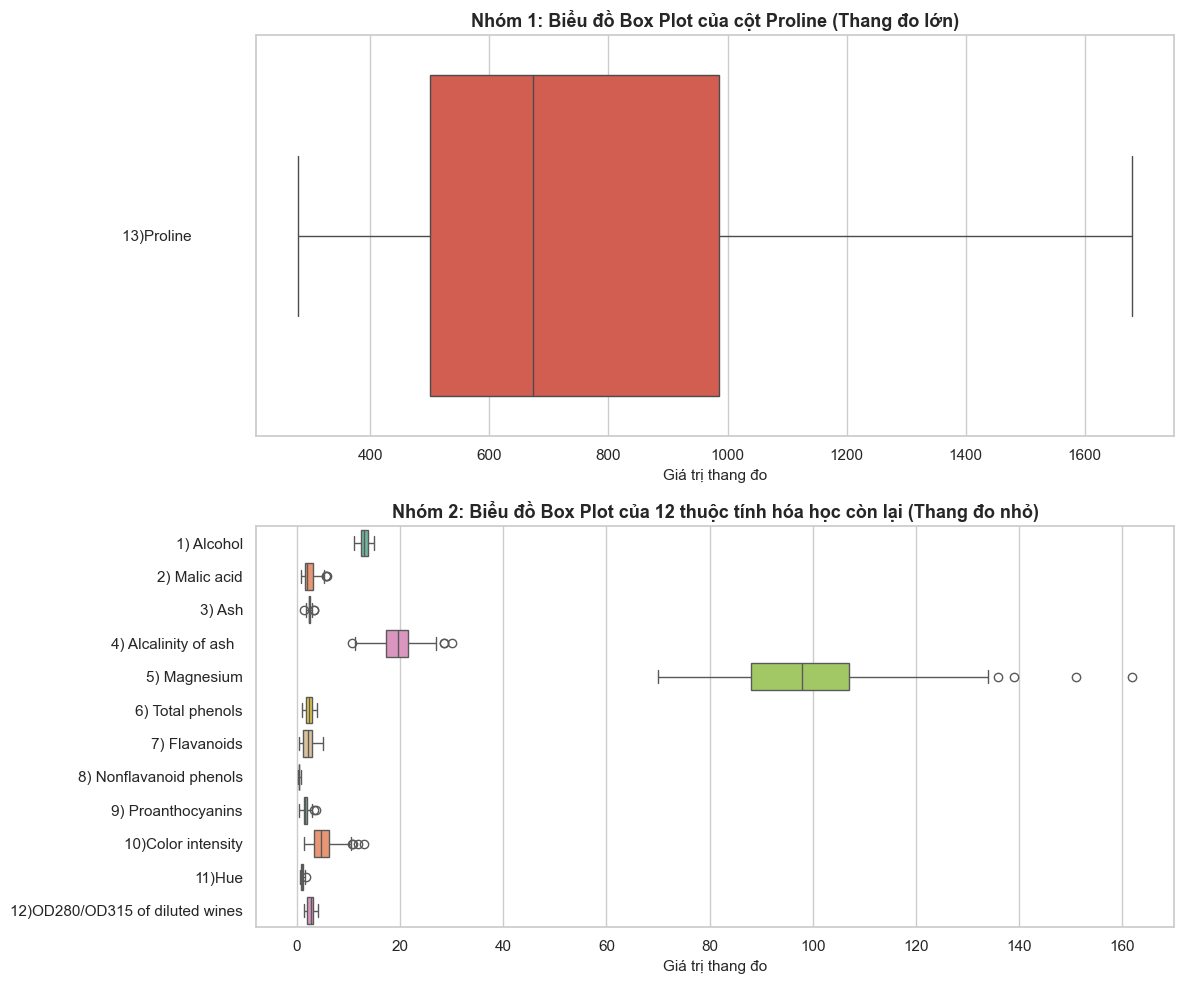

In [30]:
# 2. Chia các cột thành 2 nhóm dựa trên thang đo
# Nhóm 1: Cột Proline có giá trị lớn
cols_group1 = ['13)Proline            ']

# Nhóm 2: 12 cột còn lại có giá trị nhỏ
cols_group2 = [col for col in df_features.columns if col not in cols_group1]

# 3. Vẽ 2 biểu đồ Box Plot song song (chia thành 2 hàng trên 1 cửa sổ)
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 10), sharex=False)
sns.set_theme(style="whitegrid")

# Biểu đồ cho nhóm 1 (Proline)
sns.boxplot(data=df_features[cols_group1], orient='h', ax=axes[0], color='#e74c3c')
axes[0].set_title('Nhóm 1: Biểu đồ Box Plot của cột Proline (Thang đo lớn)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Giá trị thang đo', fontsize=11)

# Biểu đồ cho nhóm 2 (12 cột còn lại)
sns.boxplot(data=df_features[cols_group2], orient='h', ax=axes[1], palette='Set2')
axes[1].set_title('Nhóm 2: Biểu đồ Box Plot của 12 thuộc tính hóa học còn lại (Thang đo nhỏ)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Giá trị thang đo', fontsize=11)

# Tinh chỉnh giao diện
plt.tight_layout()
plt.show()

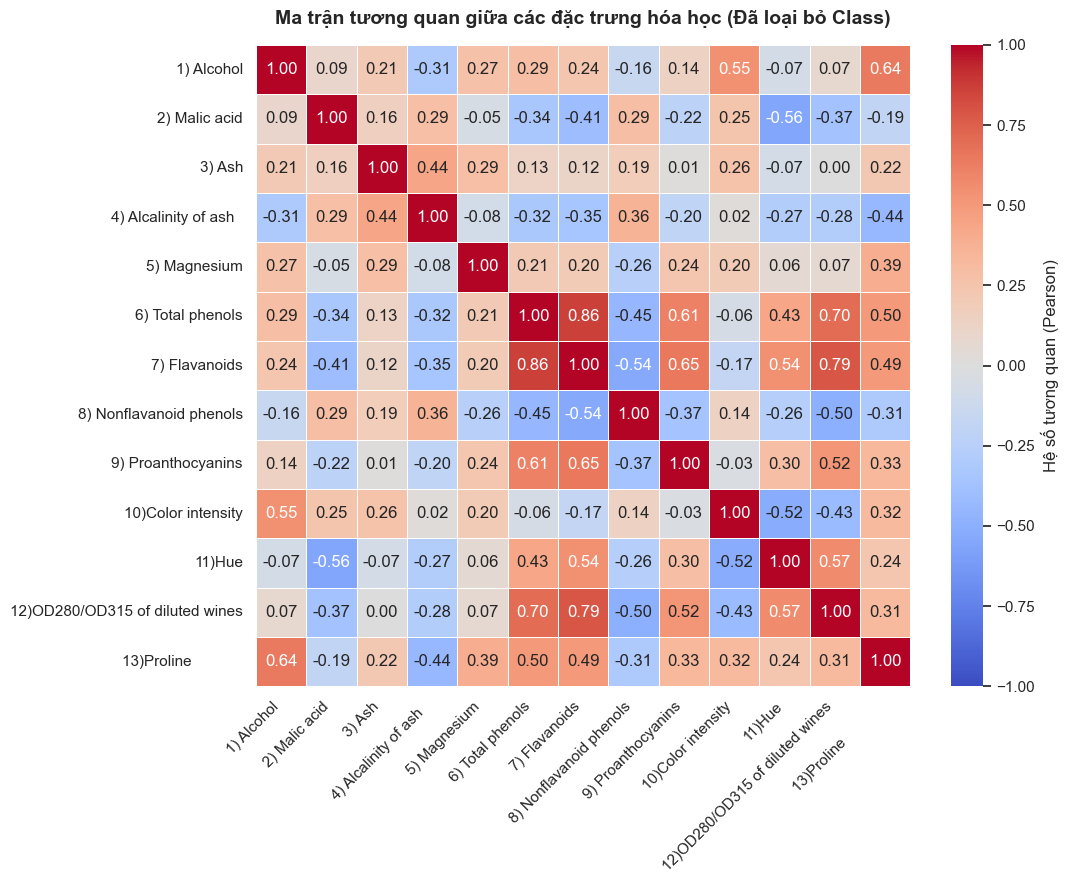

In [31]:
# 2. Loại bỏ cột 'Class' trước khi tính ma trận tương quan
df_features = df.drop(columns=['Class'])
corr_matrix = df_features.corr()

# 3. Thiết lập biểu đồ Heatmap cho 13 đặc trưng
plt.figure(figsize=(11, 9))
sns.set_theme(style="white")

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    linewidths=0.5, 
    cbar_kws={'label': 'Hệ số tương quan (Pearson)'}
)

# Thiết lập tiêu đề và nhãn
plt.title('Ma trận tương quan giữa các đặc trưng hóa học (Đã loại bỏ Class)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Tinh chỉnh giao diện và hiển thị
plt.tight_layout()
plt.show()

<Figure size 1200x1200 with 0 Axes>

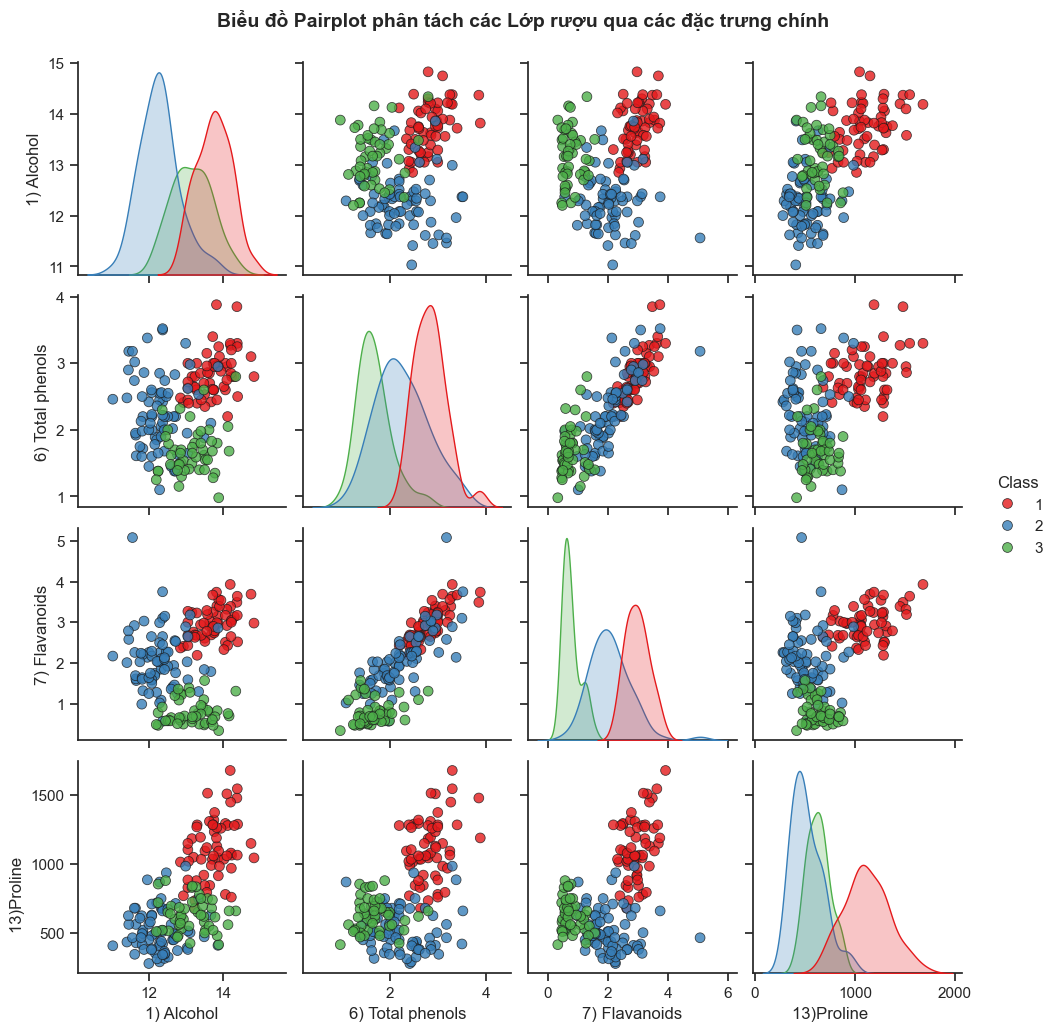

In [32]:
# 2. Chọn ra các cột đặc trưng tiêu biểu nhất để vẽ cho đỡ bị rối mắt (có kèm cột Class)
selected_cols = ['Class', '1) Alcohol', '6) Total phenols', '7) Flavanoids', '13)Proline            ']

# 3. Thiết lập và vẽ Pairplot
plt.figure(figsize=(12, 12))
sns.set_theme(style="ticks")

g = sns.pairplot(
    df[selected_cols], 
    hue='Class', 
    palette='Set1', 
    diag_kind='kde', # Biểu đồ mật độ phân phối ở đường chéo chính
    plot_kws={'alpha': 0.8, 's': 50, 'edgecolor': 'k'}
)

# Đặt tiêu đề cho toàn bộ khung biểu đồ
g.fig.suptitle('Biểu đồ Pairplot phân tách các Lớp rượu qua các đặc trưng chính', y=1.03, fontsize=14, fontweight='bold')

# Hiển thị biểu đồ
plt.show()

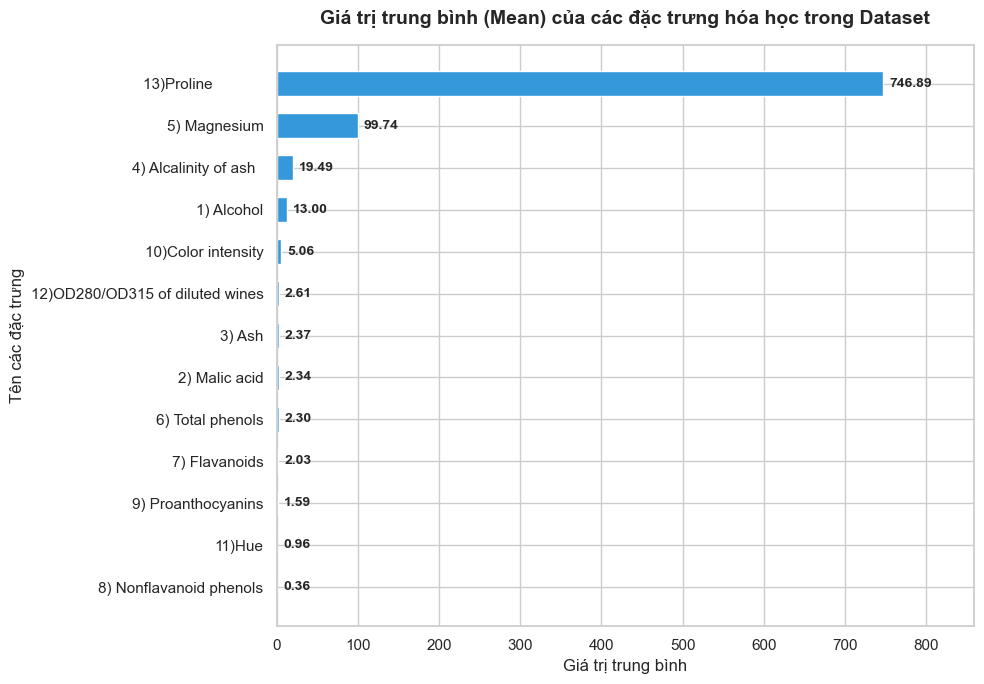

In [33]:
mean_values = df_features.mean().sort_values(ascending=True) # Sắp xếp từ thấp đến cao để dễ nhìn

# 3. Vẽ biểu đồ cột ngang thể hiện giá trị trung bình
plt.figure(figsize=(10, 7))
sns.set_theme(style="whitegrid")

bars = plt.barh(mean_values.index, mean_values.values, color='#3498db', height=0.6)

# Gắn giá trị cụ thể lên đầu mỗi thanh cột
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + (max(mean_values.values) * 0.01),  # Đẩy chữ ra phía ngoài cột một chút
        bar.get_y() + bar.get_height()/2.,
        f'{width:.2f}',
        va='center', ha='left', fontsize=10, fontweight='bold'
    )

# Thiết lập tiêu đề và nhãn
plt.title('Giá trị trung bình (Mean) của các đặc trưng hóa học trong Dataset', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Giá trị trung bình', fontsize=12)
plt.ylabel('Tên các đặc trưng', fontsize=12)
plt.xlim(0, max(mean_values.values) * 1.15)  # Mở rộng trục x để chứa số hiển thị

# Tinh chỉnh giao diện
plt.tight_layout()
plt.show()

--- CHỈ SỐ SKEWNESS (ĐỘ LỆCH) ---
1) Alcohol: Skewness = -0.051 (Đối xứng tốt)
2) Malic acid: Skewness = 1.031 (Lệch phải vừa/nặng)
3) Ash: Skewness = -0.175 (Đối xứng tốt)
4) Alcalinity of ash  : Skewness = 0.211 (Đối xứng tốt)
5) Magnesium: Skewness = 1.089 (Lệch phải vừa/nặng)
6) Total phenols: Skewness = 0.086 (Đối xứng tốt)
7) Flavanoids: Skewness = 0.025 (Đối xứng tốt)
8) Nonflavanoid phenols: Skewness = 0.446 (Đối xứng tốt)
9) Proanthocyanins: Skewness = 0.513 (Lệch phải vừa/nặng)
10)Color intensity: Skewness = 0.861 (Lệch phải vừa/nặng)
11)Hue: Skewness = 0.021 (Đối xứng tốt)
12)OD280/OD315 of diluted wines: Skewness = -0.305 (Đối xứng tốt)
13)Proline            : Skewness = 0.761 (Lệch phải vừa/nặng)


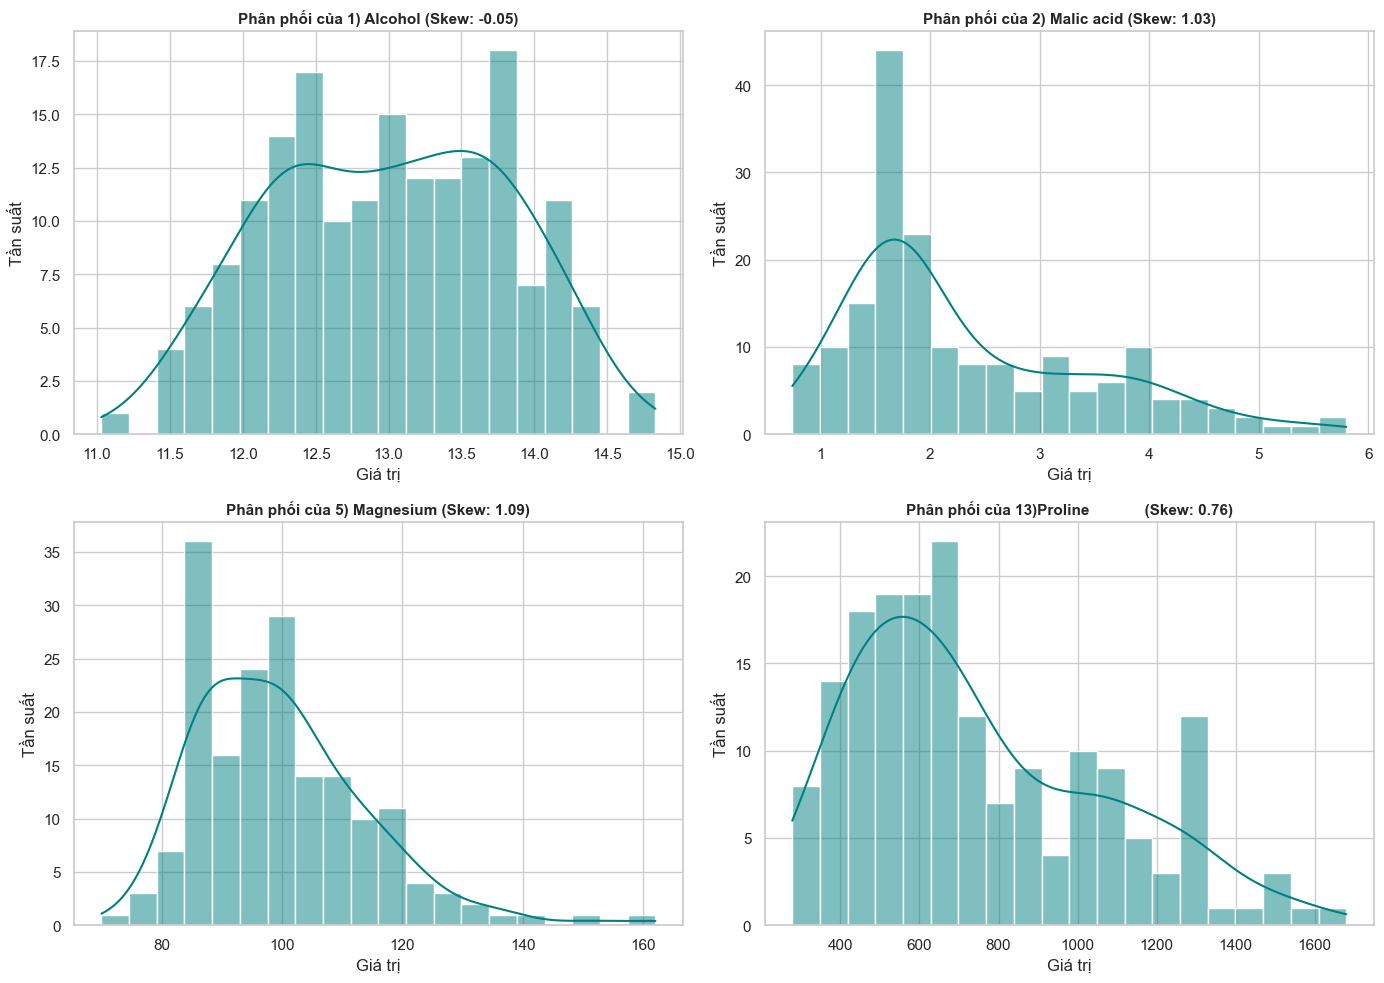

In [34]:
X = df.drop(columns=['Class'])

# 2. Tính chỉ số Skewness cho từng đặc trưng
skew_values = X.apply(lambda x: skew(x))
print("--- CHỈ SỐ SKEWNESS (ĐỘ LỆCH) ---")
for col, val in skew_values.items():
    status = "Đối xứng tốt" if abs(val) < 0.5 else ("Lệch phải vừa/nặng" if val > 0 else "Lệch trái vừa/nặng")
    print(f"{col}: Skewness = {val:.3f} ({status})")

# 3. Vẽ biểu đồ Histogram kết hợp đường KDE cho một số biến tiêu biểu
plt.figure(figsize=(14, 10))
sns.set_theme(style="whitegrid")

cols_to_plot = ['1) Alcohol', '2) Malic acid', '5) Magnesium', '13)Proline            ']
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(X[col], kde=True, color='teal', bins=20)
    plt.title(f'Phân phối của {col} (Skew: {skew_values[col]:.2f})', fontsize=11, fontweight='bold')
    plt.xlabel('Giá trị')
    plt.ylabel('Tần suất')

plt.tight_layout()
plt.show()

In [35]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df.drop(columns=['Class'])

# 2. Tính chỉ số VIF cho từng đặc trưng
vif_data = pd.DataFrame()
vif_data['Đặc trưng (Feature)'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Sắp xếp theo thứ tự VIF giảm dần
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

print("--- BẢNG CHỈ SỐ VIF (ĐA CỘNG TUYẾN) ---")
print(vif_data)

--- BẢNG CHỈ SỐ VIF (ĐA CỘNG TUYẾN) ---
                Đặc trưng (Feature)         VIF
0                        1) Alcohol  206.189057
1                            3) Ash  165.640370
2            4) Alcalinity of ash     73.141564
3                      5) Magnesium   67.364868
4                  6) Total phenols   62.786935
5   12)OD280/OD315 of diluted wines   54.539165
6                            11)Hue   45.398407
7                     7) Flavanoids   35.535602
8                9) Proanthocyanins   17.115665
9                10)Color intensity   17.022272
10          8) Nonflavanoid phenols   16.636708
11           13)Proline               16.370828
12                    2) Malic acid    8.925541


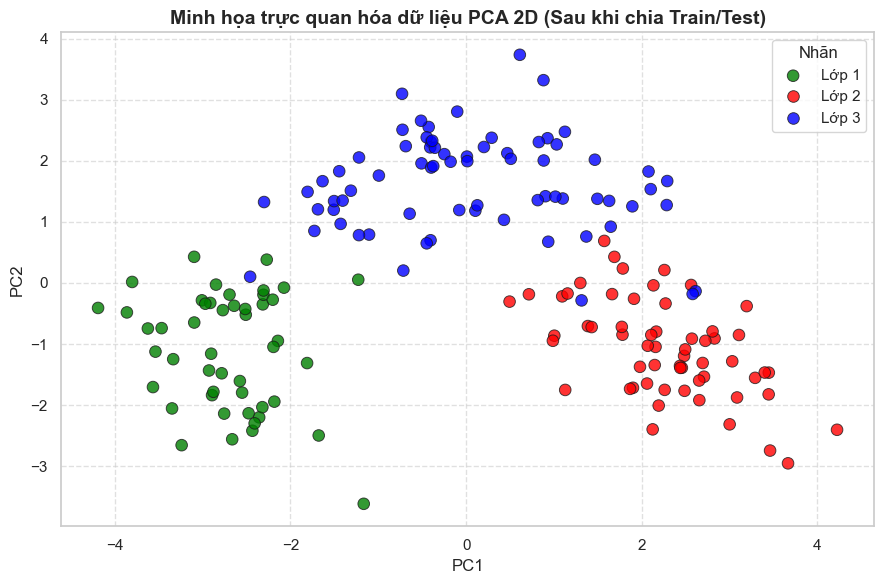

In [46]:
# Tách đặc trưng và nhãn
X = df.drop(columns=['Class']) 
y = df['Class']                

# 2. Chia tập dữ liệu Train / Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Trỏ thẳng vào thư mục 'output' đã có sẵn
out_dir = r"..\output"

# 4. Lưu X, y train và X, y test thành 2 file CSV RIÊNG BIỆT
train_df = X_train.copy()
train_df.insert(0, 'Class', y_train)
train_df.to_csv(os.path.join(out_dir, 'train_data.csv'), index=False)

test_df = X_test.copy()
test_df.insert(0, 'Class', y_test)
test_df.to_csv(os.path.join(out_dir, 'test_data.csv'), index=False)

# 5. Chuẩn hóa dữ liệu (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Giảm chiều PCA xuống 2D
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 7. Lưu dữ liệu đã Scaled & PCA thành 2 file CSV
df_train_pca = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
df_train_pca['Class'] = y_train.values
df_train_pca.to_csv(os.path.join(out_dir, 'X_train_scaled_pca.csv'), index=False)

df_test_pca = pd.DataFrame(X_test_pca, columns=['PC1', 'PC2'])
df_test_pca['Class'] = y_test.values
df_test_pca.to_csv(os.path.join(out_dir, 'X_test_scaled_pca.csv'), index=False)

# 8. Trực quan hóa dữ liệu PCA 2D
df_pca_all = pd.concat([df_train_pca, df_test_pca], axis=0).reset_index(drop=True)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Class', 
    palette=['red', 'blue', 'green'], 
    data=df_pca_all, 
    s=70, alpha=0.8, edgecolor='k'
)

plt.title('Minh họa trực quan hóa dữ liệu PCA 2D (Sau khi chia Train/Test)', fontsize=14, fontweight='bold')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Nhãn', labels=['Lớp 1', 'Lớp 2', 'Lớp 3'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()